# Brachistochrone GKP preparation under cavity loss

The time-optimal Hamiltonian $H_\mathrm{opt}$ from `quantum_brachistochrone_hamiltonian` drives
$\ket{\mathrm{vac}} \to \ket{\psi_f}$ in $T = \theta_B / E$, where $\theta_B$ is the Bures angle and $E$ is the energy bound.
Here we keep $H_\mathrm{opt}$ fixed and add dissipation through the Lindblad master equation

$$
\dot\rho = -i[H_\mathrm{opt}, \rho] + \sum_k \mathcal{D}[L_k]\rho,
\qquad
\mathcal{D}[L]\rho = L\rho L^\dagger - \tfrac{1}{2}\{L^\dagger L, \rho\}.
$$

The jump operators are
$L_1 = \sqrt{\kappa(1+n_\mathrm{th})}\,a$ (loss),
$L_2 = \sqrt{\kappa n_\mathrm{th}}\,a^\dagger$ (thermal excitation), and
$L_3 = \sqrt{2\kappa_\phi}\,a^\dagger a$ (pure dephasing).
With this convention $\kappa$ is the energy decay rate and $\kappa_\phi$ is the decay rate of the Fock coherence $\ket{0}\!\bra{1}$.

**Units.** Time is measured in units of $1/E$, so every rate is quoted as $\kappa/E$.

**First-order check.** Let $\ket{\psi(t)}$ be the ideal (unitary) trajectory and define the tracking fidelity
$F_\mathrm{track}(t) = \bra{\psi(t)}\rho(t)\ket{\psi(t)}$. Differentiating gives
$\dot F_\mathrm{track} = \bra{\psi}\sum_k \mathcal{D}[L_k]\rho\ket{\psi}$ exactly, and replacing $\rho \to \ket{\psi}\!\bra{\psi}$ gives the leading-order result

$$
1 - F_\mathrm{track}(t) \approx \int_0^t \sum_k \Big(\langle L_k^\dagger L_k\rangle - |\langle L_k\rangle|^2\Big)\,dt' .
$$

Because $\ket{\psi(T)} = \ket{\psi_f}$ up to a global phase, at $t = T$ this is the target infidelity.
For pure loss the integrand is $\kappa(\langle n\rangle - |\langle a\rangle|^2)$; for dephasing it is $2\kappa_\phi \operatorname{Var}(n)$.

In [1]:
%load_ext autoreload
%autoreload 2

import inspect
import os
import time

import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import jaxquantum as jqt
import matplotlib.pyplot as plt
import numpy as np

from gkp_optimal_control.animation import animate_wigner
from gkp_optimal_control.brachistochrone import quantum_brachistochrone_hamiltonian
from gkp_optimal_control.hamiltonians import cavity_operators
from gkp_optimal_control.plotting import plot_photon_number, plot_wigner, set_plot_style
from gkp_optimal_control.states import gkp_states
from gkp_optimal_control.utils import to_ket, to_qarray, wigner_trajectory

set_plot_style()

print(f"JAX {jax.__version__} | backend: {jax.default_backend()} | complex dtype: {jnp.ones(1, dtype=jnp.complex128).dtype}")
print(f"jqt.mesolve{inspect.signature(jqt.mesolve)}")

JAX 0.10.0 | backend: cpu | complex dtype: complex128
jqt.mesolve(H: Union[jaxquantum.core.qarray.Qarray, Callable[[float], jaxquantum.core.qarray.Qarray]], rho0: jaxquantum.core.qarray.Qarray, tlist: jax.jaxlib._jax.Array, saveat_tlist: Optional[jax.jaxlib._jax.Array] = None, c_ops: Optional[jaxquantum.core.qarray.Qarray] = None, solver_options: Optional[jaxquantum.core.solvers.SolverOptions] = None) -> jaxquantum.core.qarray.Qarray


In [2]:
# Hilbert space and GKP code
n_fock = 80
gkp_delta = 0.3
gkp_cutoff = 10
gkp_alpha = jnp.sqrt(jnp.pi / 2)
gkp_beta = jnp.sqrt(jnp.pi / 2) * 1j

energy_bound = 1.0

# Loss model. Rates are relative to energy_bound because time is in units of 1/E.
kappa_over_E = 0.02          # single-photon loss rate for the focus run
kappa_phi_over_E = 0.0       # pure dephasing rate
n_th = 0.0                   # thermal occupation of the bath
kappa_sweep_over_E = np.array([1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1])

# Time grids. The sweep grid only needs to resolve <n(t)> for the first-order integral.
n_steps = 301
n_steps_sweep = 101

# Phase-space plotting
x_bound = 5.0
y_bound = 5.0
grid_points = 200

fig_dir = "../figs/brachistochrone_loss"
vid_dir = "../vids/brachistochrone_loss"
os.makedirs(fig_dir, exist_ok=True)

In [3]:
vac = jqt.basis(n_fock, 0)

gkp_0, gkp_1 = gkp_states(n_fock, gkp_alpha, gkp_beta, gkp_delta, gkp_cutoff)
targets = {
    r"0_L": gkp_0,
    # r"1_L": gkp_1,
    # r"+_L": (gkp_0 + gkp_1).unit(),
    # r"-_L": (gkp_0 - gkp_1).unit(),
    # r"+i_L": (gkp_0 + 1j * gkp_1).unit(),
    # r"-i_L": (gkp_0 - 1j * gkp_1).unit(),
}

print(f"Effective GKP squeezing: {float(-10 * jnp.log10(gkp_delta**2)):.2f} dB")

Effective GKP squeezing: 10.46 dB


## Helpers

Collapse operators are built as raw `jnp` arrays from `cavity_operators`, so the first-order formula can use them directly.
They cross into the `Qarray` layer only inside `run_mesolve`.

In [4]:
a_op, adag_op, n_op = cavity_operators(n_fock)  # raw jnp arrays


def collapse_operators(kappa, kappa_phi=0.0, n_th=0.0):
    # Raw jump operators, shape (n_ops, n_fock, n_fock).
    ops = [jnp.sqrt(kappa * (1.0 + n_th)) * a_op]
    if n_th > 0.0:
        ops.append(jnp.sqrt(kappa * n_th) * adag_op)
    if kappa_phi > 0.0:
        ops.append(jnp.sqrt(2.0 * kappa_phi) * n_op)
    return jnp.stack(ops)


def to_c_ops(raw_ops):
    # Newer jaxquantum takes a batched Qarray; older versions take a list.
    ops = [jqt.Qarray.create(op) for op in raw_ops]
    return jqt.Qarray.from_list(ops) if hasattr(jqt.Qarray, "from_list") else ops


def run_sesolve(h, psi0, tlist):
    # Ideal trajectory as raw kets, shape (T, n).
    return jnp.asarray(jqt.sesolve(h, psi0, tlist).data).reshape(len(tlist), -1)


def run_mesolve(h, psi0, tlist, raw_ops):
    # Lossy trajectory as raw density matrices, shape (T, n, n).
    result = jqt.mesolve(h, psi0.to_dm(), tlist, c_ops=to_c_ops(raw_ops))
    n = psi0.data.shape[0]
    return jnp.asarray(result.data).reshape(len(tlist), n, n)


def target_fidelity(rhos, psi):
    return jnp.real(jnp.einsum("i,tij,j->t", psi.conj(), rhos, psi))


def tracking_fidelity(rhos, psis):
    return jnp.real(jnp.einsum("ti,tij,tj->t", psis.conj(), rhos, psis))


def dm_expect(rhos, op):
    return jnp.real(jnp.einsum("ij,tji->t", op, rhos))


def ket_expect(psis, op):
    return jnp.einsum("ti,ij,tj->t", psis.conj(), op, psis)


def purity(rhos):
    return jnp.real(jnp.einsum("tij,tji->t", rhos, rhos))


def dm_trace(rhos):
    return jnp.real(jnp.einsum("tii->t", rhos))


def cumulative_trapezoid(y, t):
    increments = 0.5 * (y[1:] + y[:-1]) * jnp.diff(t)
    return jnp.concatenate([jnp.zeros(1, dtype=increments.dtype), jnp.cumsum(increments)])


def first_order_infidelity(psis, raw_ops, tlist):
    # Integral of sum_k <L_k^dag L_k> - |<L_k>|^2 along the ideal trajectory.
    rate = jnp.zeros(psis.shape[0])
    for op in raw_ops:
        rate = rate + jnp.real(ket_expect(psis, op.conj().T @ op)) - jnp.abs(ket_expect(psis, op)) ** 2
    return cumulative_trapezoid(rate, tlist)

In [5]:
vac_ket = to_ket(vac)

h_opt = {}
t_min = {}

for label, target in targets.items():
    h, T = quantum_brachistochrone_hamiltonian(vac_ket, to_ket(target), energy_bound=energy_bound)
    h_opt[label] = h if isinstance(h, jqt.Qarray) else jqt.Qarray.create(jnp.asarray(h))
    t_min[label] = float(T)
    print(f"  vac -> |{label}>:  T = {t_min[label]:.4f} / E")

  vac -> |0_L>:  T = 0.9569 / E


## Validation: $\kappa = 0$ must reproduce `sesolve`

In [6]:
check_label = r"0_L"
tlist_chk = jnp.linspace(0.0, t_min[check_label], 51)
psi_f_chk = to_ket(targets[check_label])

psis_chk = run_sesolve(h_opt[check_label], vac, tlist_chk)
rhos_chk = run_mesolve(h_opt[check_label], vac, tlist_chk, collapse_operators(0.0))
rho_ideal_chk = jnp.einsum("ti,tj->tij", psis_chk, psis_chk.conj())

print(f"max |rho_me - |psi><psi||     = {float(jnp.max(jnp.abs(rhos_chk - rho_ideal_chk))):.2e}")
print(f"F(T), sesolve                 = {float(jnp.abs(psi_f_chk.conj() @ psis_chk[-1]) ** 2):.10f}")
print(f"F(T), mesolve (kappa = 0)     = {float(target_fidelity(rhos_chk[-1:], psi_f_chk)[0]):.10f}")
print(f"max |Tr rho - 1|              = {float(jnp.max(jnp.abs(dm_trace(rhos_chk) - 1))):.2e}")

100% |██████████████████████████████████████████████| [00:00<00:00, 33143.45%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 5014.83%/s]


max |rho_me - |psi><psi||     = 1.30e-07
F(T), sesolve                 = 0.9999999915
F(T), mesolve (kappa = 0)     = 0.9999999702
max |Tr rho - 1|              = 4.44e-16


## Focus run: one target at $\kappa/E$ = `kappa_over_E`

In [7]:
focus_label = r"0_L"

h = h_opt[focus_label]
T = t_min[focus_label]
psi_f = to_ket(targets[focus_label])
raw_ops = collapse_operators(kappa_over_E * energy_bound, kappa_phi_over_E * energy_bound, n_th)
tlist = jnp.linspace(0.0, T, n_steps)

t0 = time.perf_counter()
psis = run_sesolve(h, vac, tlist)
t_se = time.perf_counter() - t0

t0 = time.perf_counter()
rhos = run_mesolve(h, vac, tlist, raw_ops)
_ = float(jnp.real(rhos[-1, 0, 0]))  # force evaluation before timing
t_me = time.perf_counter() - t0

F_target_ideal = jnp.abs(psis.conj() @ psi_f) ** 2
F_target = target_fidelity(rhos, psi_f)
F_track = tracking_fidelity(rhos, psis)
infid_pred = first_order_infidelity(psis, raw_ops, tlist)
n_ideal = jnp.real(ket_expect(psis, n_op))
n_lossy = dm_expect(rhos, n_op)
pur = purity(rhos)

print(f"|{focus_label}>, kappa/E = {kappa_over_E:g}, kappa_phi/E = {kappa_phi_over_E:g}, n_th = {n_th:g}")
print(f"  sesolve: {t_se:.2f} s | mesolve: {t_me:.2f} s")
print(f"  1 - F(T), master equation   = {1 - float(F_target[-1]):.4e}")
print(f"  1 - F(T), first order       = {float(infid_pred[-1]):.4e}")
print(f"  kappa * T * <n>_avg         = {kappa_over_E * energy_bound * T * float(jnp.mean(n_ideal)):.4e}")
print(f"  purity at T                 = {float(pur[-1]):.6f}")
print(f"  max |Tr rho - 1|            = {float(jnp.max(jnp.abs(dm_trace(rhos) - 1))):.2e}")

100% |██████████████████████████████████████████████| [00:00<00:00, 76636.29%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 3223.51%/s]


|0_L>, kappa/E = 0.02, kappa_phi/E = 0, n_th = 0
  sesolve: 0.79 s | mesolve: 0.88 s
  1 - F(T), master equation   = 3.5041e-02
  1 - F(T), first order       = 3.6773e-02
  kappa * T * <n>_avg         = 3.6812e-02
  purity at T                 = 0.934168
  max |Tr rho - 1|            = 2.03e-14


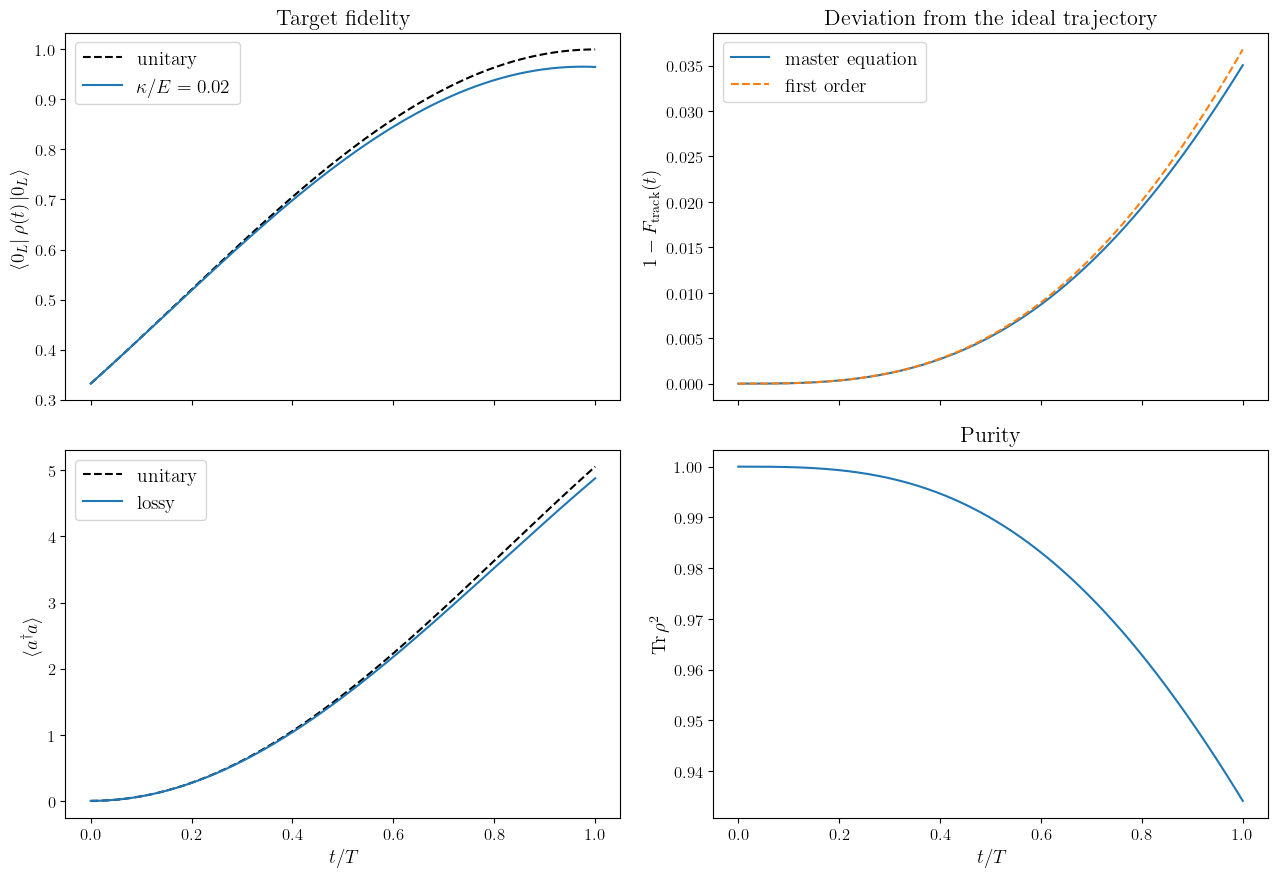

In [8]:
s = np.asarray(tlist) / T
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

ax = axes[0, 0]
ax.plot(s, F_target_ideal, "k--", label="unitary")
ax.plot(s, F_target, label=rf"$\kappa/E = {kappa_over_E:g}$")
ax.set_ylabel(rf"$\bra{{{focus_label}}}\rho(t)\ket{{{focus_label}}}$")
ax.set_title("Target fidelity")
ax.legend()

ax = axes[0, 1]
ax.plot(s, 1 - F_track, label="master equation")
ax.plot(s, infid_pred, "--", label="first order")
ax.set_ylabel(r"$1 - F_\mathrm{track}(t)$")
ax.set_title("Deviation from the ideal trajectory")
ax.legend()

ax = axes[1, 0]
ax.plot(s, n_ideal, "k--", label="unitary")
ax.plot(s, n_lossy, label="lossy")
ax.set_xlabel(r"$t / T$")
ax.set_ylabel(r"$\langle a^\dagger a \rangle$")
ax.legend()

ax = axes[1, 1]
ax.plot(s, pur)
ax.set_xlabel(r"$t / T$")
ax.set_ylabel(r"$\mathrm{Tr}\,\rho^2$")
ax.set_title("Purity")

fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"loss_trajectory_{focus_label}_kappa{kappa_over_E:g}.pdf"), bbox_inches="tight")
plt.show()

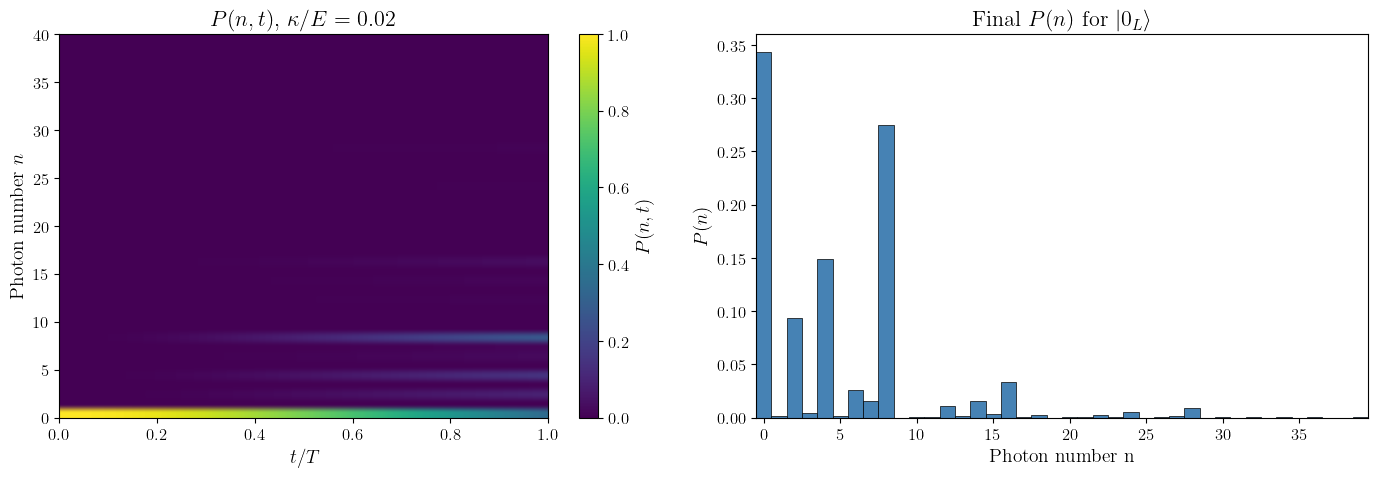

In [9]:
populations = np.asarray(jnp.real(jnp.diagonal(rhos, axis1=1, axis2=2)))  # (T, n_fock)

fig, (ax_heatmap, ax_hist) = plt.subplots(1, 2, figsize=(14, 5))
im = ax_heatmap.imshow(
    populations.T,
    extent=(0.0, 1.0, 0, n_fock - 1),
    aspect="auto",
    origin="lower",
    cmap="viridis",
)
fig.colorbar(im, ax=ax_heatmap, label=r"$P(n, t)$")
ax_heatmap.set_xlabel(r"$t / T$")
ax_heatmap.set_ylabel(r"Photon number $n$")
ax_heatmap.set_ylim(0, 40)
ax_heatmap.set_title(rf"$P(n, t)$, $\kappa/E = {kappa_over_E:g}$")

plot_photon_number(to_qarray(rhos[-1]), ax=ax_hist, max_n=40, title=rf"Final $P(n)$ for $\ket{{{focus_label}}}$")

fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"loss_photon_distribution_{focus_label}_kappa{kappa_over_E:g}.pdf"), bbox_inches="tight")
plt.show()

## Final Wigner functions: ideal target vs. lossy endpoints

100% |███████████████████████████████████████████████| [00:00<00:00, 6088.94%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 5330.23%/s]


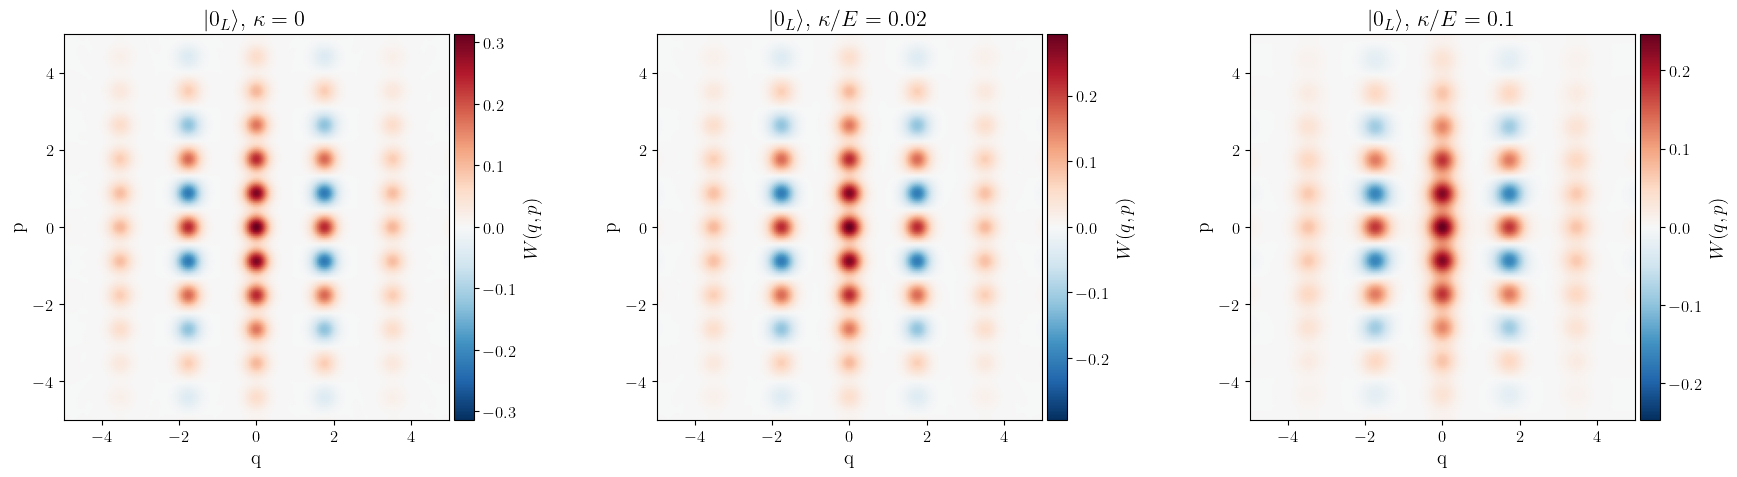

In [10]:
wigner_kappas_over_E = [kappa_over_E, 0.1]
tlist_end = jnp.linspace(0.0, T, 11)

final_states = {r"\kappa = 0": targets[focus_label]}
for kE in wigner_kappas_over_E:
    ops = collapse_operators(kE * energy_bound, kappa_phi_over_E * energy_bound, n_th)
    rho_T = run_mesolve(h, vac, tlist_end, ops)[-1]
    final_states[rf"\kappa/E = {kE:g}"] = to_qarray(rho_T)

fig, axes = plt.subplots(1, len(final_states), figsize=(6 * len(final_states), 5))
for ax, (name, state) in zip(axes, final_states.items()):
    plot_wigner(state, x_bound=x_bound, y_bound=y_bound, ax=ax, grid_points=grid_points, title=rf"$\ket{{{focus_label}}}$, ${name}$")

fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"loss_final_wigners_{focus_label}.pdf"), bbox_inches="tight")
plt.show()

In [12]:
make_movie = True  # Wigner movie of the lossy trajectory (needs ffmpeg)

if make_movie:
    stride = max(1, n_steps // 150)
    xvec, yvec, frames = wigner_trajectory(rhos[::stride], x_bound, y_bound, grid_points=grid_points)
    animate_wigner(
        frames, xvec, yvec,
        title=rf"$\ket{{{focus_label}}}$, $\kappa/E = {kappa_over_E:g}$",
        save_path=os.path.join(vid_dir, f"vac_to_gkp_{focus_label}_kappa{kappa_over_E:g}.mp4"),
        dpi=200,
    )

## Sweep: final infidelity vs. $\kappa/E$ for all six cardinal states

Dashed lines are the first-order prediction, which is linear in $\kappa$.
Departure from it marks where multiple-jump and back-action effects matter.

In [13]:
sweep_results = {}

for label, target in targets.items():
    t0 = time.perf_counter()
    h_s, T_s = h_opt[label], t_min[label]
    psi_f_s = to_ket(target)
    tl = jnp.linspace(0.0, T_s, n_steps_sweep)
    psis_s = run_sesolve(h_s, vac, tl)

    infid_sim, infid_1st = [], []
    for kE in kappa_sweep_over_E:
        ops = collapse_operators(float(kE) * energy_bound, kappa_phi_over_E * energy_bound, n_th)
        rho_T = run_mesolve(h_s, vac, tl, ops)[-1:]
        infid_sim.append(1.0 - float(target_fidelity(rho_T, psi_f_s)[0]))
        infid_1st.append(float(first_order_infidelity(psis_s, ops, tl)[-1]))

    sweep_results[label] = (np.array(infid_sim), np.array(infid_1st))
    print(f"  |{label}>: {time.perf_counter() - t0:.1f} s")

100% |██████████████████████████████████████████████| [00:00<00:00, 82842.27%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 4896.74%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 4812.96%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 4752.16%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 4866.40%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 4367.75%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 3205.75%/s]

  |0_L>: 4.9 s


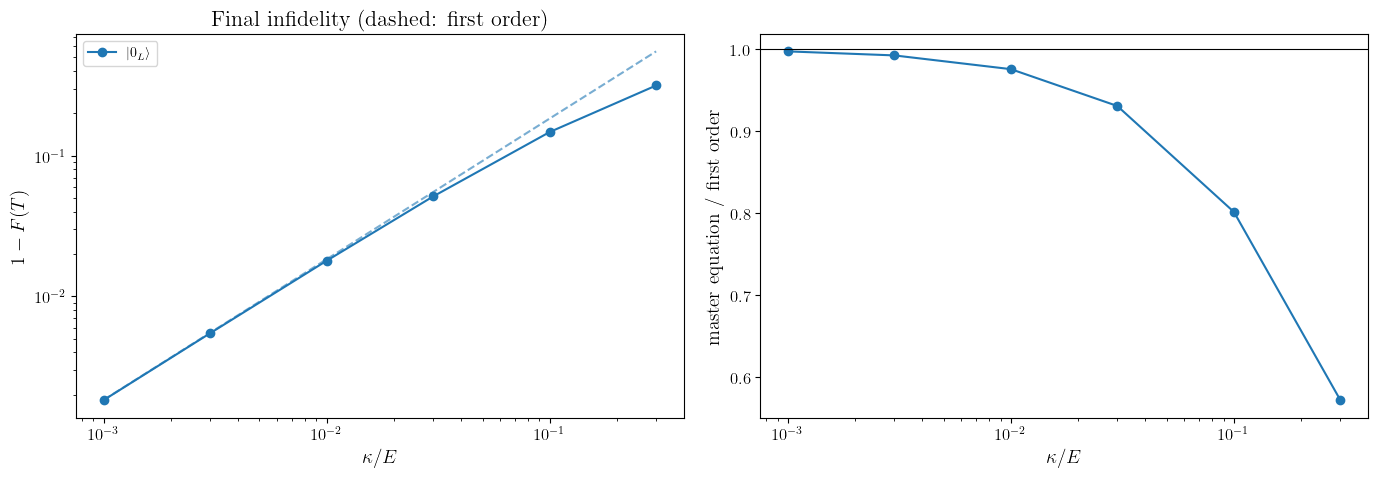

kappa/E for 1 - F = 0.01:
  |0_L>: 5.527e-03
kappa/E for 1 - F = 0.1:
  |0_L>: 6.421e-02


In [14]:
fig, (ax, ax_ratio) = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.tab10(np.arange(len(sweep_results)))

for color, (label, (sim, first)) in zip(colors, sweep_results.items()):
    ax.loglog(kappa_sweep_over_E, sim, "o-", color=color, label=rf"$\ket{{{label}}}$")
    ax.loglog(kappa_sweep_over_E, first, "--", color=color, alpha=0.6)
    ax_ratio.semilogx(kappa_sweep_over_E, sim / first, "o-", color=color, label=rf"$\ket{{{label}}}$")

ax.set_xlabel(r"$\kappa / E$")
ax.set_ylabel(r"$1 - F(T)$")
ax.set_title("Final infidelity (dashed: first order)")
ax.legend(fontsize=10)

ax_ratio.axhline(1.0, color="k", lw=0.8)
ax_ratio.set_xlabel(r"$\kappa / E$")
ax_ratio.set_ylabel("master equation / first order")

fig.tight_layout()
fig.savefig(os.path.join(fig_dir, "loss_sweep_infidelity.pdf"), bbox_inches="tight")
plt.show()

# Loss budget: kappa/E at which each target reaches a given infidelity (log-log interpolation).
for threshold in (1e-2, 1e-1):
    print(f"kappa/E for 1 - F = {threshold:g}:")
    for label, (sim, _) in sweep_results.items():
        if sim[0] < threshold < sim[-1]:
            kE = np.exp(np.interp(np.log(threshold), np.log(sim), np.log(kappa_sweep_over_E)))
            print(f"  |{label}>: {kE:.3e}")
        else:
            print(f"  |{label}>: outside sweep range")

## Channel comparison: loss vs. dephasing vs. thermal loss

Same rate $\gamma/E$ = `kappa_over_E` for each channel, applied to the focus target.

100% |██████████████████████████████████████████████| [00:00<00:00, 76454.68%/s]
100% |███████████████████████████████████████████████| [00:00<00:00, 4604.27%/s]


  loss                         1 - F = 3.5041e-02   (first order 3.6774e-02)


100% |█████████████████████████████████████████████████| [00:02<00:00, 45.35%/s]


  dephasing                    1 - F = -7.2047e+60   (first order 5.9063e-01)


100% |███████████████████████████████████████████████| [00:00<00:00, 3296.42%/s]


  loss, $n_\mathrm{th}=0.05$   1 - F = 3.9192e-02   (first order 4.1409e-02)


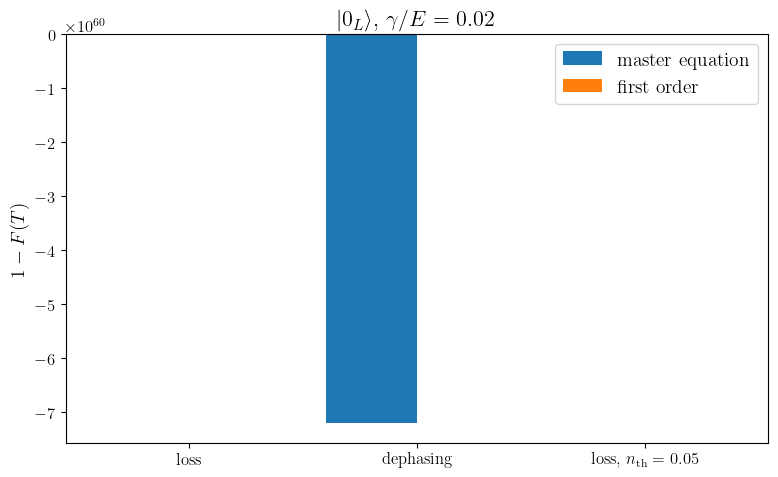

In [15]:
gamma = kappa_over_E * energy_bound
channels = {
    "loss": dict(kappa=gamma),
    "dephasing": dict(kappa=0.0, kappa_phi=gamma),
    r"loss, $n_\mathrm{th}=0.05$": dict(kappa=gamma, n_th=0.05),
}

tl = jnp.linspace(0.0, T, n_steps_sweep)
psis_c = run_sesolve(h, vac, tl)

channel_sim, channel_1st = {}, {}
for name, kw in channels.items():
    ops = collapse_operators(**kw)
    channel_sim[name] = 1.0 - float(target_fidelity(run_mesolve(h, vac, tl, ops)[-1:], psi_f)[0])
    channel_1st[name] = float(first_order_infidelity(psis_c, ops, tl)[-1])
    print(f"  {name:28s} 1 - F = {channel_sim[name]:.4e}   (first order {channel_1st[name]:.4e})")

x = np.arange(len(channels))
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - 0.2, list(channel_sim.values()), width=0.4, label="master equation")
ax.bar(x + 0.2, list(channel_1st.values()), width=0.4, label="first order")
ax.set_xticks(x)
ax.set_xticklabels(list(channels.keys()))
ax.set_ylabel(r"$1 - F(T)$")
ax.set_title(rf"$\ket{{{focus_label}}}$, $\gamma/E = {kappa_over_E:g}$")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f"loss_channel_comparison_{focus_label}.pdf"), bbox_inches="tight")
plt.show()

## Notes

- $H_\mathrm{opt}$ acts only on $\mathrm{span}\{\ket{\mathrm{vac}}, \ket{\psi_f^\perp}\}$. After a photon jump the state leaves that plane, and the Hamiltonian
  stops steering it, so the brachistochrone has no mechanism to recover lost population. It is a loss-blind baseline.
- Loss only lowers photon number, so the Fock truncation needs no more headroom than the unitary case. Still check `n_fock` convergence before trusting small infidelities.
- The first-order integrand $\langle n\rangle - |\langle a\rangle|^2$ is set by the photon-number profile of the trajectory. Comparing it against ECD/SNAP circuits at equal duration
  is the natural next step, once those circuits are simulated with the same collapse operators.